In [5]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import KNNImputer


os.makedirs("datasets", exist_ok=True)

df = pd.read_csv('data.tsv', sep="\t", header=None, names=['url', 'name', 'price', 'width', 'ratio', 'pressure', 'tread', 'sidewall'])

print(df.shape)
display(df.head())
print(df.dtypes)
print(df.isna().sum())

(150, 8)


,url,name,price,width,ratio,pressure,tread,sidewall
0,https://simpletire.com/brands/mickey-thompson-...,Mickey Thompson Baja Legend MTZ,$485.99,LT37,13.50R,50,22.0,Blackwall
1,https://simpletire.com/brands/mickey-thompson-...,Mickey Thompson Baja Legend MTZ,$481.99,LT37,13.50R,50,22.0,Blackwall
2,https://simpletire.com/brands/mickey-thompson-...,Mickey Thompson Baja Legend MTZ,$346.96,LT315,70R,65,21.0,Raised White Lettering
3,https://simpletire.com/brands/mickey-thompson-...,Mickey Thompson Baja Legend MTZ,$453.59,LT33,12.50R,65,21.0,Blackwall
4,https://simpletire.com/brands/mickey-thompson-...,Mickey Thompson Baja Legend MTZ,$289.96,LT275,70R,80,20.0,Blackwall


url             str
name            str
price           str
width           str
ratio           str
pressure      int64
tread       float64
sidewall        str
dtype: object
url         0
name        0
price       0
width       0
ratio       0
pressure    0
tread       0
sidewall    0
dtype: int64


In [6]:
df['price_usd'] = df['price'].str.replace('$', '', regex=False).astype(float)
df["price_usd"].describe()

bm = df["url"].str.extract(r"/brands/([a-z0-9-]+)-tires/([^#]+)#")
df["brand"] = bm[0]
df["model"] = bm[1]

size = df["url"].str.extract(r"tireSize=([^&]*)")[0]
df['rim'] = size.str.extract(r"(\d+)c?$")[0].astype(float)

# veľkosť je len v URL, potrebuješ ju na rozpoznanie duplicít
df["size"] = size

print(df.duplicated(subset=["model", "size"]).sum())   # čakám 2

df = df.drop_duplicates(subset=["model", "size"], keep="first").reset_index(drop=True)

df['is_LT'] = df['width'].str.startswith("LT").astype(int)

df['flotation'] = df['ratio'].str.contains(r"\.").astype(int)

df['width_mm'] = df['width'].str.replace("LT", "").astype(float).where(df['flotation'] == 0)

df['ratio_percent'] = df['ratio'].str.replace(r"[A-Z]+$", "", regex=True).astype(float).where(df['flotation'] == 0)


2


price_usd         0
width_mm         22
ratio_percent    22
rim               0
pressure          0
tread             0
dtype: int64


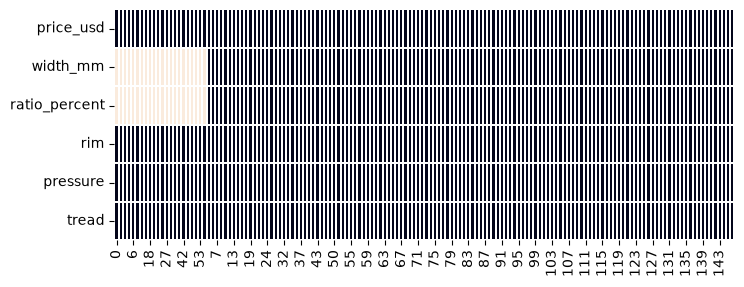

In [7]:
cols = ["price_usd", "width_mm", "ratio_percent", "rim", "pressure", "tread"]

df[cols].isna().sum(axis=1).value_counts()

print(df[cols].isna().sum())
has_nan = df[cols].isna().any(axis=1)
df[has_nan]["model"].value_counts()

plt.figure(figsize=(8, 3))
sns.heatmap(df[cols].isna().sort_values(cols, ascending=False).T, cbar=False, linewidths=0.1, linecolor="white")
plt.show()

In [8]:
df['fl_diameter_in'] = df['width'].str.replace("LT", "").astype(float).where(df['flotation'] == 1)
df['fl_width_in'] = df['ratio'].str.replace(r"[A-Z]+$", "", regex=True).astype(float).where(df['flotation'] == 1)

df['width_conv'] = df["width_mm"].fillna((df["fl_width_in"] * 25.4).round())
df['ratio_conv'] = df['ratio_percent'].fillna((((df['fl_diameter_in'] - df['rim']) / 2) / df['fl_width_in'] * 100).round())

feat = ["rim", "pressure", "tread", "is_LT"]
targets = ["width_mm", "ratio_percent"]
sub = df[feat + targets]

scaler = MinMaxScaler().fit(sub)                        # naučí sa min a max každého stĺpca
scaled = scaler.transform(sub)                          # všetko na 0–1
filled = KNNImputer(n_neighbors=5).fit_transform(scaled)  # doplní NaN podľa 5 susedov
back = scaler.inverse_transform(filled)                 # späť na mm, %, palce...
knn = pd.DataFrame(back, columns=sub.columns, index=sub.index)

df["width_knn"] = knn["width_mm"]
df["ratio_knn"] = knn["ratio_percent"]

f = df["flotation"] == 1
display(df.loc[f, ["width_conv", "width_knn", "ratio_conv", "ratio_knn"]].round(1).head(8))
print((df["width_knn"] - df["width_conv"])[f].abs().mean())    # priemerná chyba šírky
print((df["ratio_knn"] - df["ratio_conv"])[f].abs().mean())    # priemerná chyba profilu

,width_conv,width_knn,ratio_conv,ratio_knn
0,343.0,307.0,70.0,71.0
1,343.0,307.0,74.0,71.0
3,318.0,299.0,52.0,61.0
5,267.0,301.0,86.0,72.0
6,267.0,301.0,76.0,72.0
11,318.0,307.0,80.0,71.0
12,394.0,299.0,58.0,61.0
15,343.0,307.0,85.0,71.0


36.54545454545455
5.454545454545452


price_usd: 0  (hranice -104.0 – 650.0)
price_usd: 0  (z-score > 3)
width_conv: 2  (hranice 153.8 – 363.8)
width_conv: 1  (z-score > 3)
ratio_conv: 0  (hranice 20.0 – 100.0)
ratio_conv: 0  (z-score > 3)
rim: 0  (hranice 14.0 – 22.0)
rim: 0  (z-score > 3)
pressure: 0  (hranice 5.0 – 125.0)
pressure: 0  (z-score > 3)
tread: 0  (hranice 1.5 – 26.8)
tread: 0  (z-score > 3)


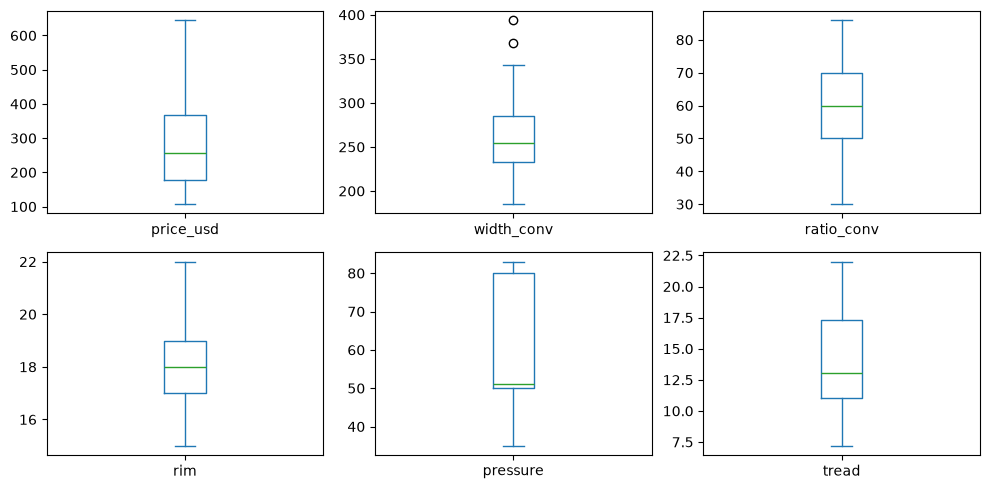

In [9]:
num = ["price_usd", "width_conv", "ratio_conv", "rim", "pressure", "tread"]

def iqr_fences(s):
    q1, q3 = s.quantile([.25, .75])
    i = q3 - q1
    return q1 - 1.5 * i, q3 + 1.5 * i


for x in num:
    low, high = iqr_fences(df[x])
    outside = (df[x] < low) | (df[x] > high)

    print(f"{x}: {outside.sum()}  (hranice {low:.1f} – {high:.1f})")

    z = (df[x] - df[x].mean()) / df[x].std()
    print(f"{x}: {(z.abs() > 3).sum()}  (z-score > 3)")


df[num].plot(kind="box", subplots=True, layout=(2, 3), figsize=(10, 5))
plt.tight_layout()
plt.savefig("vystupy/boxploty.png", dpi=150, bbox_inches="tight")

In [10]:
keep = ["brand", "is_LT", "flotation", "price_usd",
        "width_conv", "ratio_conv", "width_knn", "ratio_knn",
        "rim", "pressure", "tread"]
base = df[keep].copy()

display(base["price_usd"].describe())
display(pd.cut(base["price_usd"], 3).value_counts().sort_index())
display(pd.qcut(base["price_usd"], 3).value_counts().sort_index())


count    148.000000
mean     283.558108
std      125.437776
min      107.000000
25%      178.740000
50%      255.885000
75%      367.242500
max      644.990000
Name: price_usd, dtype: float64

price_usd
(106.462, 286.33]    83
(286.33, 465.66]     49
(465.66, 644.99]     16
Name: count, dtype: int64

price_usd
(106.999, 194.99]    50
(194.99, 338.66]     49
(338.66, 644.99]     49
Name: count, dtype: int64

In [11]:
A = base.copy()
A = A.drop(columns=["width_knn", "ratio_knn"])

labels = ['low', 'medium', 'high']

# 5 columns into 3 classes
A["price_class"] = pd.qcut(A["price_usd"], 3, labels=labels)
A["width_class"] = pd.qcut(A["width_conv"], 3, labels=labels)
A["ratio_class"] = pd.qcut(A["ratio_conv"], 3, labels=labels)
A["rim_class"]   = pd.qcut(A["rim"], 3, labels=labels)
A["tread_class"] = pd.qcut(A["tread"], 3, labels=labels)

A["pressure_class"] = pd.cut(A["pressure"], [0, 60, 75, 200], labels=["low", "medium", "high"])

A = A.drop(columns=["price_usd", "width_conv", "ratio_conv", "rim", "tread", "pressure"])

A = A.astype(str)
A.head()

A[["tread_class", "pressure_class"]].apply(lambda s: s.value_counts())

,tread_class,pressure_class
high,28,49
low,65,88
medium,55,11


In [12]:
B = base.copy()
B = B.drop(columns=["width_conv", "ratio_conv"])

B[["width_knn", "ratio_knn"]] = B[["width_knn", "ratio_knn"]].round()

num = ["price_usd", "width_knn", "ratio_knn", "rim", "pressure", "tread"]

# Winsorization, changing extreme values to the nearest fence
original = B[num].copy()
for c in num:
    lo, hi = iqr_fences(B[c])
    B[c] = B[c].clip(lo, hi)

print((B[num] != original).sum())


B = pd.get_dummies(B, columns=["brand"], dtype=int)

scaler_B = MinMaxScaler()
B[num] = scaler_B.fit_transform(B[num])

price_usd    0
width_knn    0
ratio_knn    0
rim          0
pressure     0
tread        0
dtype: int64


In [ ]:
A.to_csv("datasets/dataset_A_categorical.csv", index=False)
B.to_csv("datasets/dataset_B_numeric.csv", index=False)

# prvých 50 riadkov (zadanie to dovoľuje ako ukážku)
A.head(50).to_csv("datasets/dataset_A_head50.csv", index=False)
B.head(50).to_csv("datasets/dataset_B_head50.csv", index=False)

pd.qcut(base["pressure"], 3, duplicates="drop").value_counts().sort_index()


None

None

pressure
(34.999, 50.0]    54
(50.0, 69.0]      45
(69.0, 83.0]      49
Name: count, dtype: int64